# Testing the Black Box rules on three datasets

SSIE 501 · Group 5 · Part 2

This notebook tests the model in `MODEL_SPECIFICATION.md` (Part A) against every recorded change in three independent datasets of the numerical page `BlackBox_N.php`:

| Key | Dataset | Runs | Starts at |
|---|---|---|---|
| **H** | Shared dataset, W. Zhang (`data/shared_dataset/`) | 30 × 2,000 grids | the grid the page labels "step 1" |
| **D** | Group 1 scraper runs (`data/group1_runs/`) | 61 × 2,001 grids | the Reset grid |
| **G2** | Group 2 frames (`data/group2/frames.csv`) | 1 × 41 grids | step 1 |

The Region 1 gates, the two parts of Region 2 and the strict Region 4 rule come from Marcus Washington's simulator, which was built on his own recordings, so **none of these three datasets was used to find them**.

The same numbers are produced by `analysis/11_gate_rules.py` (claims C35-C43) and re-tested by `check_claims.py`. The shared dataset is in the repository; the Group 1 and Group 2 files must be placed in `data/` first (see `data/README.md`). The outputs saved in this notebook were produced with all three present.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from blackbox.data import load_heldout, load_discovery, load_group2
from blackbox.regions import AREA
from blackbox.gate_model import GateModel, r1_target_grid
from blackbox.rule_checks import evaluate

DATA = {"H": load_heldout(), "D": load_discovery(), "G2": load_group2()}
pd.DataFrame({k: {"runs": len(v), "grids per run": len(v[0]), "steps recorded": sum(len(r) - 1 for r in v)}
              for k, v in DATA.items()}).T

,runs,grids per run,steps recorded
H,30,2000,59970
D,61,2001,122000
G2,1,41,40


## 1. Every rule, on every recorded change

`evaluate()` (in `blackbox/rule_checks.py`) walks through every pair of consecutive grids and checks each change against its region's rule:

- **Region 1:** for every change from 0-3 or 6-9, does the cell's gate predict *jump* vs *advance* correctly?
- **Region 2, minimum part** (rows 1-10 × columns 16-20): the new value must not be higher, and must be present in rows 11-20.
- **Region 2, multiply part** (rows 6-10 × columns 6-15): the new value must equal (old × some value in that part) mod 10.
- **Region 4:** every swap must leave neither cell with fewer matching neighbours and give at least one more, counted after Regions 1-3 have moved in the same step.

In [2]:
RES = {k: evaluate(v) for k, v in DATA.items()}
rows = {}
for k, r in RES.items():
    rows[k] = {
        "Region 1 gates (right / changes)": f"{r['gate_ok']:,} / {r['n_ev']:,}",
        "Region 2 minimum part (fits / changes)": f"{r['pt']['partner_found']:,} / {r['pt']['changes']:,}",
        "Region 2 minimum part: rises": r["pt"]["rises"],
        "Region 2 multiply part (fits / changes)": f"{r['fo']['product_found']:,} / {r['fo']['changes']:,}",
        "Region 4 swaps, regions in order (fit / swaps)": f"{r['sw']['strict_in_order']:,} / {r['sw']['swaps']:,}",
        "Region 4 swaps, all regions read old grid": f"{r['sw']['strict_old']:,} / {r['sw']['swaps']:,}",
    }
pd.DataFrame(rows)

,H,D,G2
Region 1 gates (right / changes),"16,046 / 16,046","32,400 / 32,400",30 / 30
Region 2 minimum part (fits / changes),"2,616 / 2,616","5,122 / 5,122",13 / 13
Region 2 minimum part: rises,0,0,0
Region 2 multiply part (fits / changes),"2,346 / 2,346","5,084 / 5,084",9 / 9
"Region 4 swaps, regions in order (fit / swaps)","2,002 / 2,002","4,022 / 4,022",9 / 9
"Region 4 swaps, all regions read old grid","2,001 / 2,002","4,014 / 4,022",9 / 9


Every rule fits every recorded change in all three datasets. The last row shows why the regions must update **in order**: if all four regions read the grid as it was at the start of the step, 9 swaps (all on a region border) would break the Region 4 rule; in order, none does.

## 2. Settled Region 1 cells: does the gate decide when a 4 or a 5 jumps?

A cell sitting at 4 or 5 whose gate agrees with its half should never move; one whose gate disagrees should jump the next time it is picked (1 chance in 100 per step).

In [3]:
tab = {}
for k, r in RES.items():
    (na, ja), (nd, jd) = r["settled"]["agree"], r["settled"]["disagree"]
    tab[k] = {"gate agrees: cell-steps": na, "gate agrees: jumps": ja,
              "gate disagrees: cell-steps": nd, "gate disagrees: jumps": jd,
              "jump rate when it disagrees": round(jd / nd, 4) if nd else None}
pd.DataFrame(tab).astype(object)

,H,D,G2
gate agrees: cell-steps,4293166.0,8761698.0,486.0
gate agrees: jumps,0.0,0.0,0.0
gate disagrees: cell-steps,106926.0,205529.0,453.0
gate disagrees: jumps,1102.0,2147.0,7.0
jump rate when it disagrees,0.0103,0.0104,0.0155


## 3. The earlier waiting-time rule, scored on the same changes

Our first version of Region 1 (in `REPORT.md`, Section 4) said a cell jumps at a random rate that depends on how long it has waited since its last change. Scored on exactly the same changes:

In [4]:
pd.DataFrame({k: {"best guess right": f"{r['wait_ok']:,} / {r['n_ev']:,} ({r['wait_ok'] / r['n_ev']:.1%})",
                  "log-likelihood per change": round(r["ll_wait"] / r["n_ev"], 3),
                  "gates: errors": r["n_ev"] - r["gate_ok"]} for k, r in RES.items()})

,H,D,G2
best guess right,"13,851 / 16,046 (86.3%)","28,015 / 32,400 (86.5%)",22 / 30 (73.3%)
log-likelihood per change,-0.33,-0.325,-0.578
gates: errors,0,0,0


## 4. The first step after Reset

Group 1's runs begin at the Reset grid itself, so they are the only data that test step 1.

In [5]:
f = RES["D"]["first"]
print(f"{f['transitions']} first steps; Region 1 changed in {f['r1_changes']} of them; the gates were right {f['r1_gate_ok']} times.")

61 first steps; Region 1 changed in 47 of them; the gates were right 47 times.


## 5. Is the Region 1 cell picked uniformly?

A Region 1 cell holding 0-3 or 6-9 always changes when it is picked, so for those cells *changed / steps spent in that state* is the chance of being picked. Uniform picking gives 1.00% for every cell.

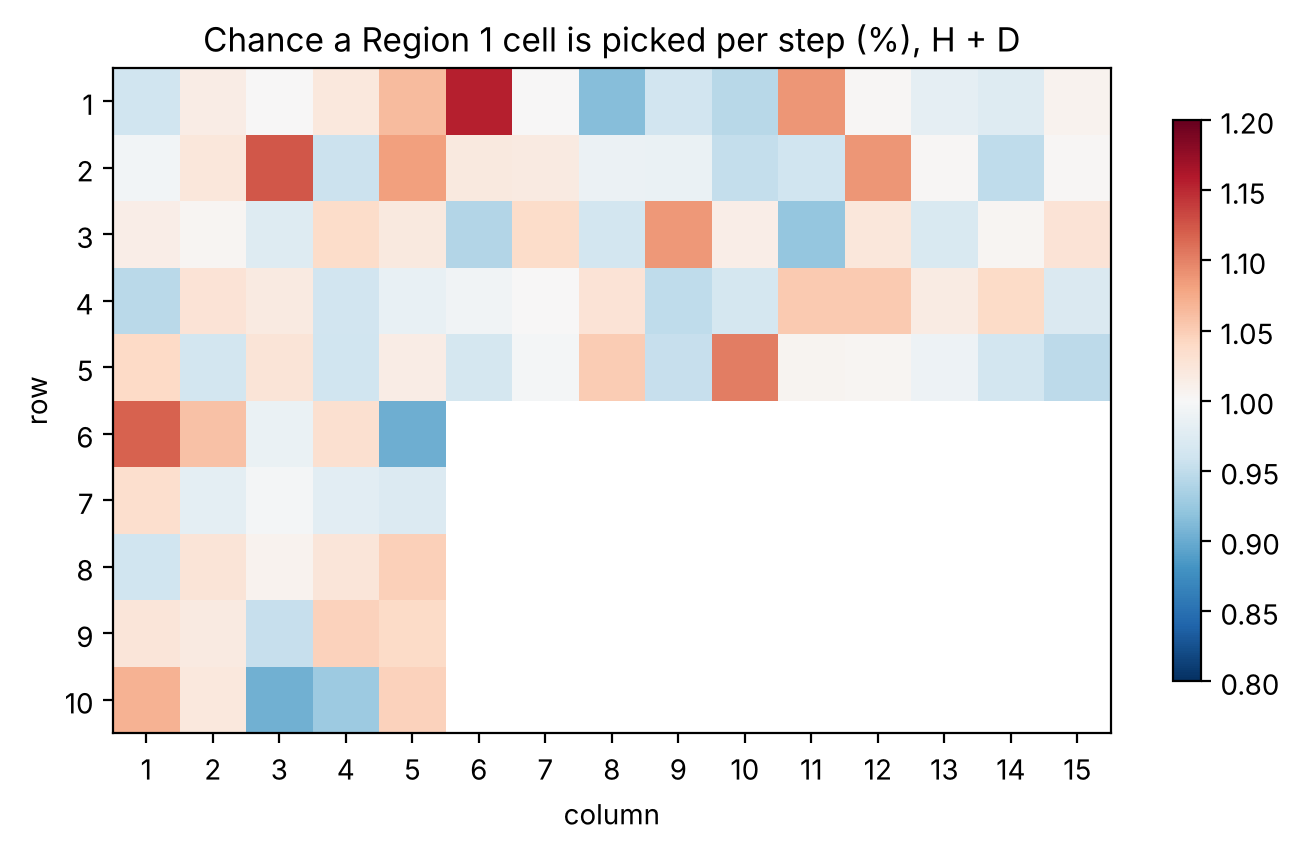

range 0.90% to 1.16%, mean 1.004%


In [6]:
R1 = AREA == 1
expo = np.zeros((20, 20)); hits = np.zeros((20, 20))
for k in ("H", "D"):
    for tr in DATA[k]:
        a, b = tr[:-1], tr[1:]
        active = R1 & ((a < 4) | ((a > 5) & (a <= 9)))
        expo += active.sum(axis=0); hits += (active & (a != b)).sum(axis=0)
rate = np.where(R1, hits / np.maximum(expo, 1) * 100, np.nan)
fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(rate[:10, :15], cmap="RdBu_r", vmin=0.8, vmax=1.2)
ax.set_xticks(range(15)); ax.set_xticklabels(range(1, 16)); ax.set_yticks(range(10)); ax.set_yticklabels(range(1, 11))
ax.set_xlabel("column"); ax.set_ylabel("row"); ax.set_title("Chance a Region 1 cell is picked per step (%), H + D")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()
print(f"range {np.nanmin(rate):.2f}% to {np.nanmax(rate):.2f}%, mean {np.nanmean(rate):.3f}%")

## 6. The rebuilt box against the real one

`GateModel` (in `blackbox/gate_model.py`) is the Part A model written as code. Started from the same 30 grids as the shared dataset (5 runs each), it should reproduce the real runs' activity and end state.

In [7]:
def H(v):
    _, c = np.unique(v, return_counts=True); p = c / c.sum(); return -(p * np.log2(p)).sum()

def summary(tr):
    ch = tr[1:] != tr[:-1]; end = tr[-1]
    s = {f"Region {a}: cells changed": ch[:, AREA == a].sum() for a in (1, 2, 3, 4)}
    s.update({f"Region {a}: end entropy (bits)": H(end[AREA == a]) for a in (1, 2, 3, 4)})
    s["Region 1: share of 4s"] = np.mean(end[AREA == 1] == 4)
    s["Region 2: share of 0s"] = np.mean(end[AREA == 2] == 0)
    return s

real = pd.DataFrame([summary(t) for t in DATA["H"]]).mean()
model = pd.DataFrame([summary(GateModel(t[0], seed=100 * k + rep).run(len(t) - 1))
                      for k, t in enumerate(DATA["H"]) for rep in range(5)]).mean()
pd.DataFrame({"rebuilt model": model, "real box (H)": real}).round(3)

,rebuilt model,real box (H)
Region 1: cells changed,539.827,571.600
Region 2: cells changed,165.287,165.400
Region 3: cells changed,1461.200,1460.767
Region 4: cells changed,132.067,133.467
Region 1: end entropy (bits),0.787,0.784
Region 2: end entropy (bits),0.042,0.042
Region 3: end entropy (bits),2.093,2.093
Region 4: end entropy (bits),3.257,3.257
Region 1: share of 4s,0.780,0.795
Region 2: share of 0s,0.994,0.995


## 7. The one remaining difference: block D of Region 1 stays busy

Region 1 changes slightly more often in the real box than in the model. Splitting the late part of each run (steps 1,001-2,000) by Region 1's four 5 × 5 blocks shows where: only **block D** (rows 6-10, columns 1-5) differs.

,A,B,C,D
real,10.9,10.8,12.8,26.0
rebuilt,10.7,10.9,12.1,14.4


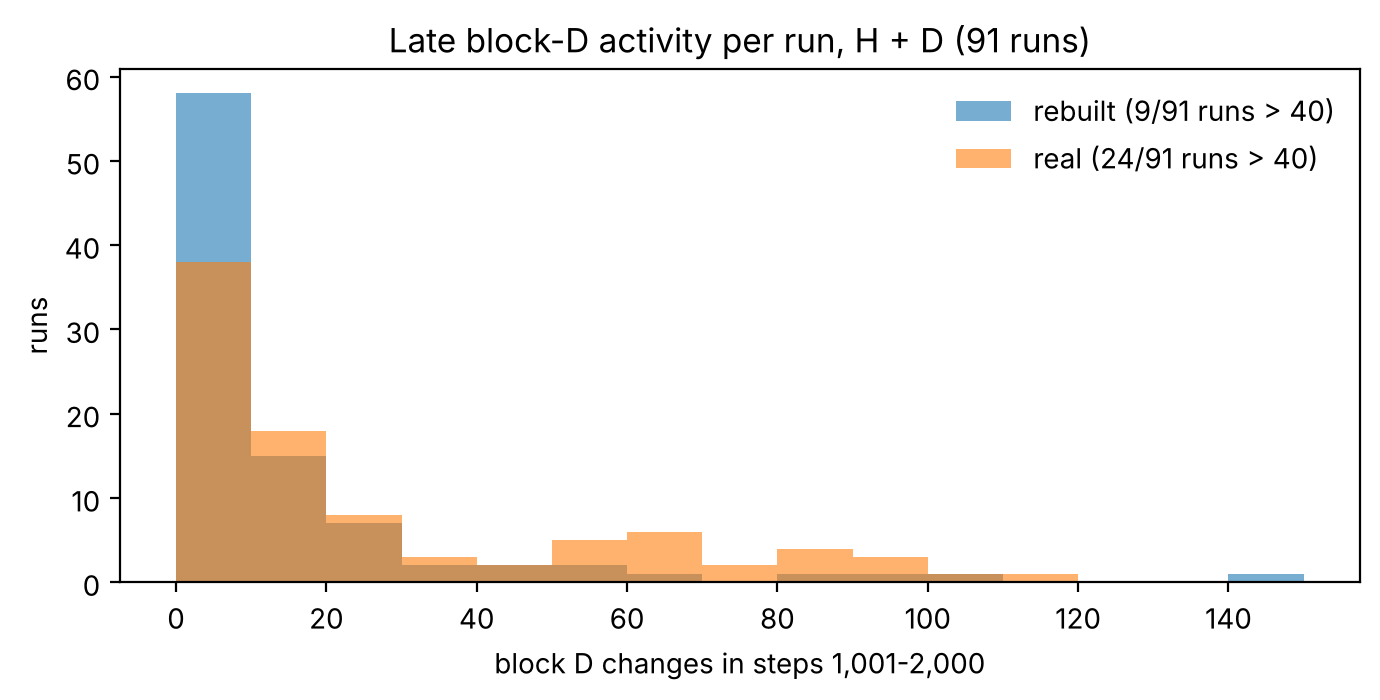

In [8]:
BLOCKS = {"A": (slice(0, 5), slice(0, 5)), "B": (slice(0, 5), slice(5, 10)),
          "C": (slice(0, 5), slice(10, 15)), "D": (slice(5, 10), slice(0, 5))}
long_runs = DATA["H"] + DATA["D"]

def late(trs):
    return {k: np.array([(t[1001:] != t[1000:-1])[:, a, b].sum() for t in trs]) for k, (a, b) in BLOCKS.items()}

real_b = late(long_runs)
model_b = late([GateModel(t[0], seed=300 + k).run(len(t) - 1) for k, t in enumerate(long_runs)])
display(pd.DataFrame({"real": {k: v.mean() for k, v in real_b.items()},
                      "rebuilt": {k: v.mean() for k, v in model_b.items()}}).round(1).T)

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.arange(0, 160, 10)
ax.hist(model_b["D"], bins=bins, alpha=0.6, label=f"rebuilt ({(model_b['D'] > 40).sum()}/{len(long_runs)} runs > 40)")
ax.hist(real_b["D"], bins=bins, alpha=0.6, label=f"real ({(real_b['D'] > 40).sum()}/{len(long_runs)} runs > 40)")
ax.set_xlabel("block D changes in steps 1,001-2,000"); ax.set_ylabel("runs"); ax.legend(frameon=False)
ax.set_title("Late block-D activity per run, H + D (91 runs)"); plt.tight_layout(); plt.show()

Every individual change still obeys the rules (Sections 1-2) and picking is uniform (Section 5), so this is not a wrong gate. It is a difference in how often block D settles into a stable state. It is the main open question left in the model, and our fresh recordings (`analysis/12_fresh_runs.py`) retest it.

## 8. The values 10-13

Region 3's table has a small tail above 9 (0.03% per draw). These values should appear only in Region 3, at about that rate once the region has been redrawn many times.

In [9]:
from blackbox.gate_model import R3_TABLE
rows = {}
for k in ("H", "D"):
    t = np.array([tr[500:] for tr in DATA[k]])
    r3 = t[:, :, AREA == 3]
    rows[k] = {"Region 3 cell-steps": r3.size, "values 10+": int((r3 >= 10).sum()),
               "share": (r3 >= 10).mean(), "values 10+ outside Region 3": int((t[:, :, AREA != 3] >= 10).sum())}
df = pd.DataFrame(rows).T
df.loc["table predicts", "share"] = R3_TABLE[10:].sum()
df

,Region 3 cell-steps,values 10+,share,values 10+ outside Region 3
H,4500000.0,977.0,0.000217,0.0
D,9156100.0,4146.0,0.000453,0.0
table predicts,NaN,NaN,0.000300,NaN


## Summary

- Region 1 gates: every jump and advance in all three datasets, and every settled cell, including the first step after Reset.
- Region 2: both parts fit every change; the minimum part never rises.
- Region 4: every swap fits the strict rule once the regions update in order 1-4.
- The rebuilt box matches the real one in all four regions; the one difference left is that block D of Region 1 stays active late in more real runs than rebuilt ones.